# AIMLZG565 Machine Learning - Assignment II
**Student:** Suraj Kumar  |  **ID:** 2026AJ05451

Five classifiers on the Breast Cancer Wisconsin (Diagnostic) dataset: Logistic Regression, Decision Tree, KNN,
Gaussian Naive Bayes and SVM, evaluated with Accuracy, AUC, Precision, Recall, F1 and MCC.

In [1]:
import json, os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix, roc_curve)
import warnings; warnings.filterwarnings("ignore")
SEED = 42

## 1. Load the dataset

In [2]:
path = "data/breast-cancer.csv" if os.path.exists("data/breast-cancer.csv") else "breast-cancer.csv"
raw = pd.read_csv(path)
print("Shape:", raw.shape)
print("Missing values:", int(raw.isna().sum().sum()))
print(raw["diagnosis"].value_counts())
raw.head()

Shape: (569, 32)
Missing values: 0
diagnosis
B    357
M    212
Name: count, dtype: int64


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Prepare features and split
Drop `id`, encode B=0 / M=1 (malignant is the positive class), stratified 80/20 split.

In [3]:
df = raw.drop(columns=["id"])
label_map = {"B": 0, "M": 1}
FEATURES = [c for c in df.columns if c != "diagnosis"]
X, y = df[FEATURES], df["diagnosis"].map(label_map)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Features:", len(FEATURES))

Train: (455, 30)  Test: (114, 30)
Features: 30


## 3. Train the five models
Scaling lives inside the pipeline for the scale-sensitive models (LR, KNN, SVM).

In [4]:
models = {
    "Logistic Regression": Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=1000, random_state=SEED))]),
    "Decision Tree": Pipeline([("clf", DecisionTreeClassifier(max_depth=5, min_samples_leaf=3, random_state=SEED))]),
    "KNN": Pipeline([("scale", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=7))]),
    "Naive Bayes": Pipeline([("clf", GaussianNB())]),
    "Support Vector Machine": Pipeline([("scale", StandardScaler()), ("clf", SVC(kernel="rbf", C=1.0, probability=True, random_state=SEED))]),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    print("fitted:", name)

fitted: Logistic Regression
fitted: Decision Tree
fitted: KNN
fitted: Naive Bayes
fitted: Support Vector Machine


## 4. Evaluation metrics
With TP, TN, FP, FN counted for the malignant (positive) class:

- Accuracy = (TP + TN) / (TP + TN + FP + FN)
- Precision = TP / (TP + FP)
- Recall = TP / (TP + FN)
- F1 = 2 * Precision * Recall / (Precision + Recall)
- MCC = (TP*TN - FP*FN) / sqrt((TP+FP)(TP+FN)(TN+FP)(TN+FN))
- AUC = area under the ROC curve built from predicted malignant probabilities

In [5]:
rows, cms, probas = [], {}, {}
for name, m in models.items():
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    cms[name], probas[name] = confusion_matrix(y_test, pred), proba
    rows.append({"ML Model Name": name,
                 "Accuracy": accuracy_score(y_test, pred), "AUC": roc_auc_score(y_test, proba),
                 "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred), "MCC": matthews_corrcoef(y_test, pred)})
results = pd.DataFrame(rows).round(4)
results

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9035,0.9471,0.9429,0.7857,0.8571,0.7926
2,KNN,0.9561,0.9825,0.9744,0.9048,0.9383,0.9058
3,Naive Bayes,0.9386,0.9934,1.0000,0.8333,0.9091,0.8715
4,Support Vector Machine,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442


In [6]:
# Cross-check: recompute metrics by hand from the confusion matrix for every model
for name, cm in cms.items():
    tn, fp, fn, tp = cm.ravel()
    acc = (tp + tn) / cm.sum()
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn)
    f1 = 2 * prec * rec / (prec + rec)
    mcc = (tp*tn - fp*fn) / np.sqrt((tp+fp)*(tp+fn)*(tn+fp)*(tn+fn))
    r = results.set_index("ML Model Name").loc[name]
    assert np.allclose([acc, prec, rec, f1, mcc], r[["Accuracy","Precision","Recall","F1","MCC"]].values.astype(float), atol=1e-4), name
    print(f"{name:24s} TN={tn:3d} FP={fp} FN={fn} TP={tp:3d}  -> manual formulas match sklearn")

Logistic Regression      TN= 71 FP=1 FN=3 TP= 39  -> manual formulas match sklearn
Decision Tree            TN= 70 FP=2 FN=9 TP= 33  -> manual formulas match sklearn
KNN                      TN= 71 FP=1 FN=4 TP= 38  -> manual formulas match sklearn
Naive Bayes              TN= 72 FP=0 FN=7 TP= 35  -> manual formulas match sklearn
Support Vector Machine   TN= 72 FP=0 FN=3 TP= 39  -> manual formulas match sklearn


## 5. Confusion matrices and ROC curves

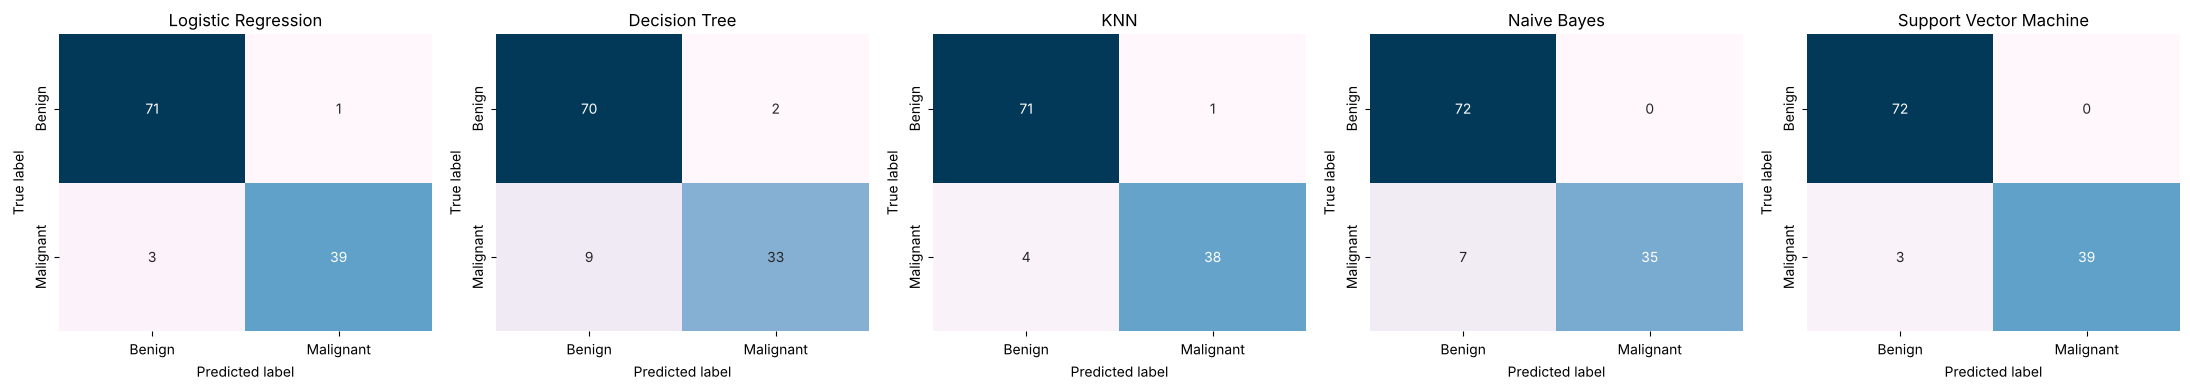

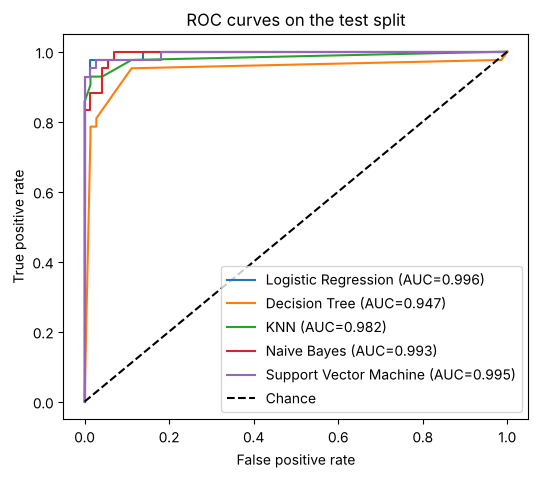

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, cm) in zip(axes, cms.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="PuBu", cbar=False, ax=ax,
                xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"])
    ax.set_title(name); ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 5))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curves on the test split")
plt.legend(loc="lower right"); plt.show()

## 6. Save models and test data (used by the Streamlit app)

In [8]:
os.makedirs("model", exist_ok=True)
for name, m in models.items():
    joblib.dump(m, os.path.join("model", name.lower().replace(" ", "_") + ".joblib"))
test_df = X_test.copy(); test_df["diagnosis"] = y_test.map({0: "B", 1: "M"})
test_df.to_csv("test_data.csv", index=False)
json.dump({"label_map": label_map, "features": FEATURES, "target": "diagnosis"}, open("model/label_map.json", "w"), indent=2)
results.to_csv("model/metrics.csv", index=False)
print(sorted(os.listdir("model")))

['decision_tree.joblib', 'knn.joblib', 'label_map.json', 'logistic_regression.joblib', 'metrics.csv', 'naive_bayes.joblib', 'support_vector_machine.joblib']


## 7. Conclusion
Support Vector Machine is the best model on this split (highest Accuracy, F1 and MCC, with no false positives),
with Logistic Regression a very close second and the highest AUC. The Decision Tree is the weakest and misses the
most malignant cases. With only 114 test rows, the SVM vs Logistic Regression gap is a single sample.